# Example of the aitlas toolbox in the context of semantic segmentation

The WHU-OHS dataset is multispectral (32 spectral bands). 

## Import the required packages

In [ ]:
from aitlas.datasets import WHUOHSDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
import matplotlib.pyplot as plt
import numpy as np 

## Visualize images and masks

New train/val/test split (60%/20%/20%)

In [ ]:
# specific bands
dataset_config = {
    "data_dir": "./data/WHU_OHS",
    "csv_file": "./data/WHU_OHS/whu_ohs_train.csv",
    "selection": "bands",
    "bands_ohs": ["B05","B10","B25","B30"]
}
dataset = WHUOHSDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 4572


Original train/val/test split

2026-03-26 10:56:40,069 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


Total number of patches: 7620


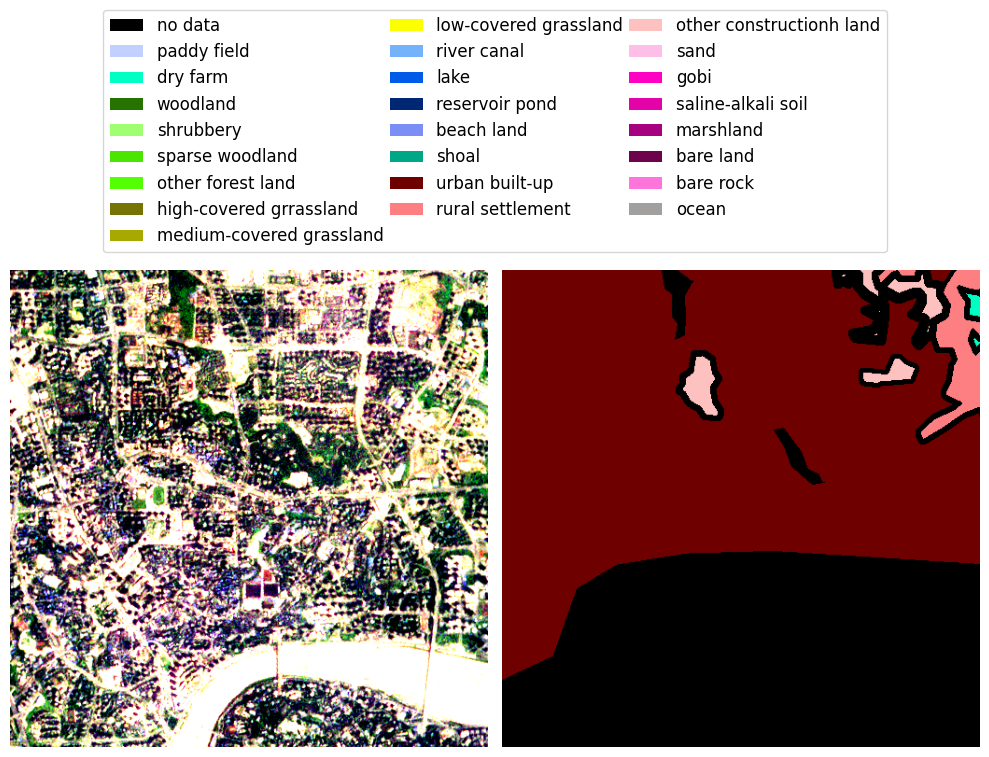

2026-03-26 10:56:40,462 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


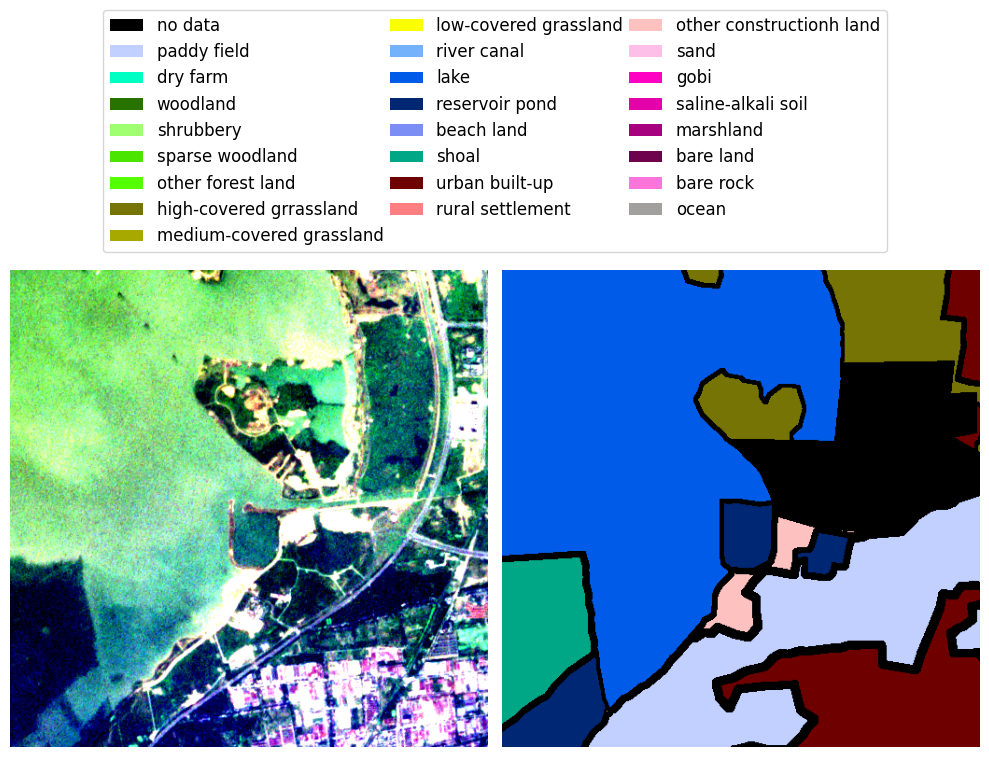

2026-03-26 10:56:40,856 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


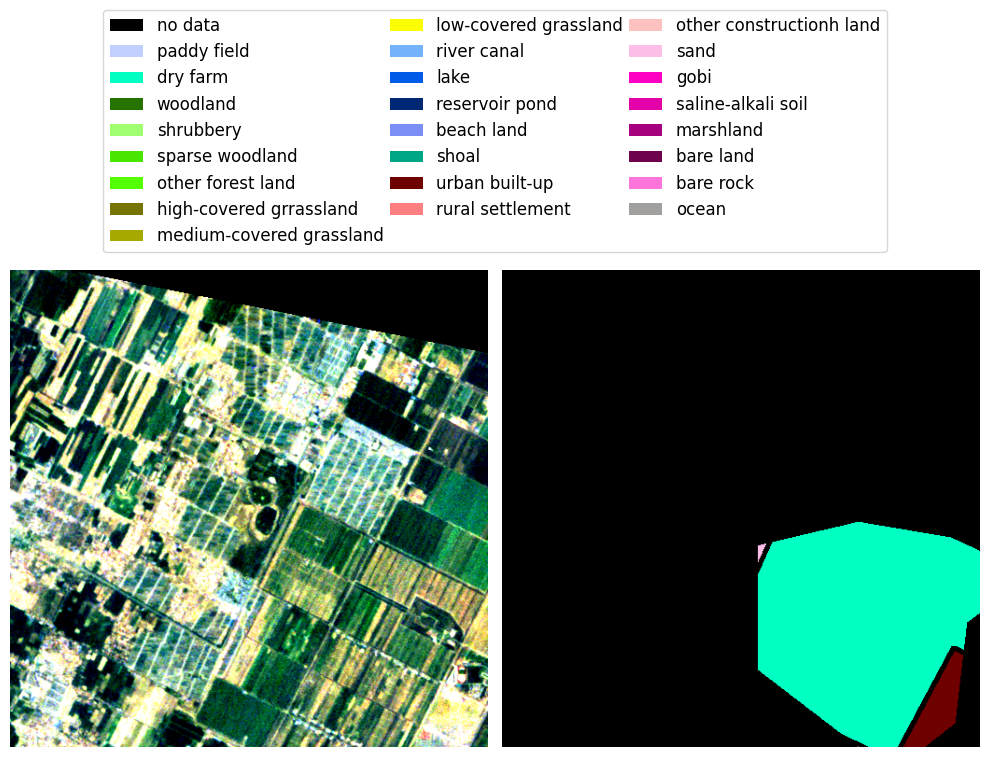

In [ ]:
# rgb images
dataset_config = {
    "data_dir": "./data/WHU_OHS",
    "selection": "rgb"
}
dataset = WHUOHSDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(300);
dataset.show_image(1500);

In [20]:
dataset.data_distribution_table()

,Number of pixels
no data,1.054748e+09
paddy field,1.432617e+08
dry farm,2.136422e+08
woodland,1.106290e+08
shrubbery,2.259399e+07
sparse woodland,1.307924e+07
other forest land,3.965825e+06
high-covered grrassland,4.997170e+07
medium-covered grassland,3.658057e+07
low-covered grassland,4.594646e+07


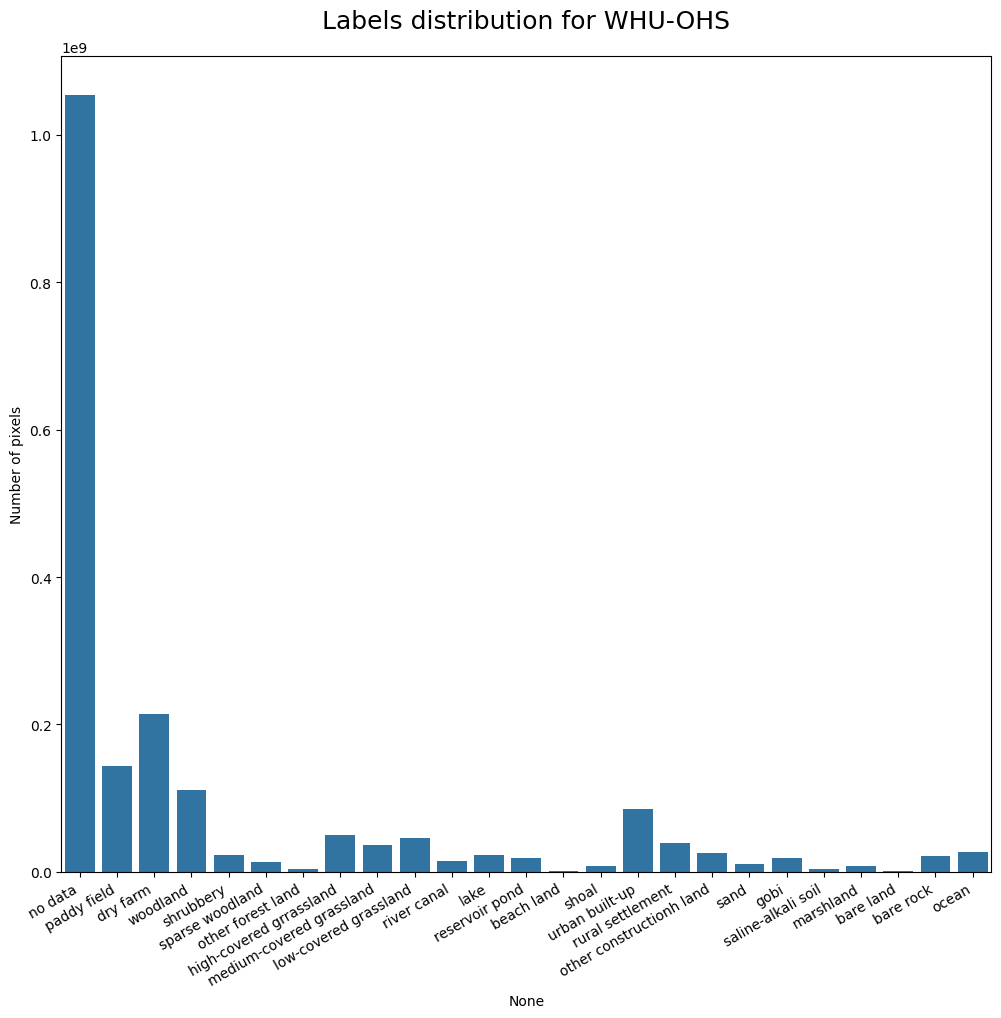

In [21]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 14,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/WHU_OHS/train",
    "selection": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = WHUOHSDataset(train_dataset_config)
len(train_dataset)

4648

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/WHU_OHS"
model_config = {
    "num_classes": 25, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [26]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-24 08:46:25,249 INFO Starting training.
training: 100%|██████████| 332/332 [01:15<00:00,  4.37it/s]
2025-03-24 08:47:41,298 INFO epoch: 1, time: 76, loss:  0.82930
testing on train set: 100%|██████████| 332/332 [01:14<00:00,  4.47it/s]
2025-03-24 08:48:56,937 INFO IOU:0.24166048616338023, IOU mean:0.047048809032112754, IOU per Class:[0.38880298 0.18007044 0.15497506 0.13927273 0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.313099   0.         0.
 0.         0.         0.         0.         0.         0.
 0.        ]
training: 100%|██████████| 332/332 [01:14<00:00,  4.47it/s]
2025-03-24 08:50:11,218 INFO epoch: 2, time: 75, loss:  0.60700
testing on train set: 100%|██████████| 332/332 [01:14<00:00,  4.47it/s]
2025-03-24 08:51:25,480 INFO IOU:0.2641051540205529, IOU mean:0.04115695752966245, IOU per Class:[0.38880298 0.17540617 0.18690589 0.17239891 0.         0.
 0.         0.         0.         0.         0.         

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/WHU_OHS/val",
    "selection": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = WHUOHSDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/WHU_OHS/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

513


2025-03-24 09:11:28,077 INFO Loading checkpoint /home/dragik/data/FAIR_EO/WHU_OHS/checkpoint.pth.tar
2025-03-24 09:11:28,402 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/WHU_OHS/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 129/129 [00:08<00:00, 14.72it/s]


[{'IOU': 0.30564140192068223,
  'IOU mean': 0.05710694665987963,
  'IOU per Class': array([0.39243092, 0.30584029, 0.26457308, 0.19118347, 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.27364591, 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ])}]

## Predictions

2025-03-24 09:20:26,803 INFO Loading checkpoint /home/dragik/data/FAIR_EO/WHU_OHS/checkpoint.pth.tar
2025-03-24 09:20:27,378 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/WHU_OHS/checkpoint.pth.tar at epoch 11
2025-03-24 09:20:27,432 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-03-24 09:20:27,838 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-03-24 09:20:28,243 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-03-24 09:20:28,651 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


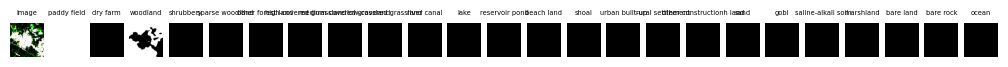

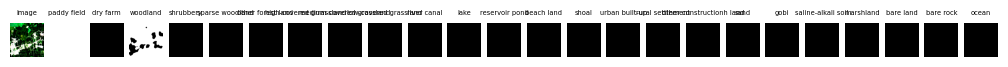

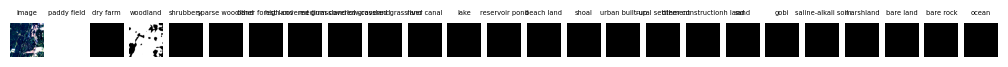

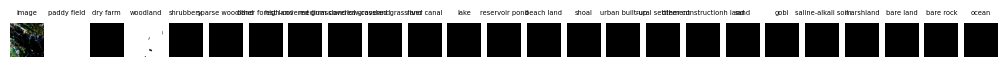

In [ ]:
model_path = "./data/WHU_OHS/checkpoint.pth.tar"
labels = ["paddy field","dry farm","woodland","shrubbery","sparse woodland","other forest land","high-covered grrassland","medium-covered grassland","low-covered grassland","river canal","lake","reservoir pond","beach land","shoal","urban built-up","rural settlement","other constructionh land","sand","gobi","saline-alkali soil","marshland","bare land","bare rock","ocean"]
transform = MinMaxNormTranspose()
plt.rcParams.update({'font.size': 4})
model.load_model(model_path)

image = image_loader('./data/WHU_OHS/test/images/test_O1_0010.tif')
Red = image[:,:,13]
Green = image[:,:,6]
Blue = image[:,:,1]
image = np.dstack([Red,Green,Blue])/10000
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/WHU_OHS/test/images/test_O1_0032.tif')
Red = image[:,:,13]
Green = image[:,:,6]
Blue = image[:,:,1]
image = np.dstack([Red,Green,Blue])/10000
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/WHU_OHS/test/images/test_O2_0103.tif')
Red = image[:,:,13]
Green = image[:,:,6]
Blue = image[:,:,1]
image = np.dstack([Red,Green,Blue])/10000
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/WHU_OHS/test/images/test_O4_0070.tif')
Red = image[:,:,13]
Green = image[:,:,6]
Blue = image[:,:,1]
image = np.dstack([Red,Green,Blue])/10000
fig = model.predict_masks(image, labels, transform)